In [ ]:
# 1. Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style (optional, but good practice)
sns.set_style("whitegrid")

# 2. Load the dataset (Make sure 'Netflix Dataset.csv' is uploaded to your Colab session)
try:
    df = pd.read_csv('Netflix Dataset.csv', encoding='latin-1')
    print("Data loaded successfully!")
except FileNotFoundError:
    print("Error: 'Netflix Dataset.csv' not found. Please upload the file to your Colab session.")
    df = None

# 3. Initial data inspection
if df is not None:
    print("\nFirst 5 rows of the dataset:")
    print(df.head())
    print("\nData Information (Columns, Non-Null Counts, Data Types):")
    df.info()

Data loaded successfully!

First 5 rows of the dataset:
  Show_Id Category  Title           Director  \
0      s1  TV Show     3%                NaN   
1      s2    Movie  07:19  Jorge Michel Grau   
2      s3    Movie  23:59       Gilbert Chan   
3      s4    Movie      9        Shane Acker   
4      s5    Movie     21     Robert Luketic   

                                                Cast        Country  \
0  JoÃ£o Miguel, Bianca Comparato, Michel Gomes, ...         Brazil   
1  DemiÃ¡n Bichir, HÃ©ctor Bonilla, Oscar Serrano...         Mexico   
2  Tedd Chan, Stella Chung, Henley Hii, Lawrence ...      Singapore   
3  Elijah Wood, John C. Reilly, Jennifer Connelly...  United States   
4  Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...  United States   

        Release_Date Rating   Duration  \
0    August 14, 2020  TV-MA  4 Seasons   
1  December 23, 2016  TV-MA     93 min   
2  December 20, 2018      R     78 min   
3  November 16, 2017  PG-13     80 min   
4    January 1, 20

In [ ]:
import pandas as pd
import numpy as np

# Load the dataset (Re-running the load step is often necessary in a new session)
# Assuming the file is still 'Netflix Dataset.csv'
try:
    df = pd.read_csv('Netflix Dataset.csv', encoding='latin-1')
except FileNotFoundError:
    print("Error: 'Netflix Dataset.csv' not found. Please upload the file to your Colab session.")
    df = None

if df is not None:
    # 1. Standardize column names
    df.columns = df.columns.str.lower()
    df.rename(columns={'show_id': 'show_id', 'category': 'type', 'type': 'genre'}, inplace=True)

    # 2. Handle Missing Values (Nulls) using the recommended assignment method (avoiding FutureWarning)
    df['director'] = df['director'].fillna('Unknown')
    df['cast'] = df['cast'].fillna('Unknown')
    df['country'] = df['country'].fillna('Unspecified')

    # Drop rows where 'release_date' is missing, as it is needed for time-series analysis
    df.dropna(subset=['release_date'], inplace=True) # inplace=True is fine here as we are on the original df

    # 3. Convert 'release_date' to a proper datetime format
    # Using 'format="mixed"' handles inconsistent date formats, including potential leading/trailing spaces
    # It's the most robust way when formats are slightly irregular or mixed.
    df['release_date'] = pd.to_datetime(df['release_date'], format='mixed', dayfirst=False, errors='coerce')

    # 4. Extract 'release_year'
    df['release_year'] = df['release_date'].dt.year

    # 5. Filter data to align with the scope (2008 to 2021)
    df_filtered = df[(df['release_year'] >= 2008) & (df['release_year'] <= 2021)].copy()

    print("Data cleaning and filtering steps successfully executed.")
    print(f"Data filtered for 2008-2021. Total records: {len(df_filtered)}")
    print("\nUpdated DataFrame Information (First 5 rows):")
    print(df_filtered.head())

# Saving the cleaned data for the next analysis steps
df_filtered.to_csv('netflix_cleaned_filtered.csv', index=False)
print("Cleaned and filtered data saved to netflix_cleaned_filtered.csv.")

Data cleaning and filtering steps successfully executed.
Data filtered for 2008-2021. Total records: 7779

Updated DataFrame Information (First 5 rows):
  show_id     type  title           director  \
0      s1  TV Show     3%            Unknown   
1      s2    Movie  07:19  Jorge Michel Grau   
2      s3    Movie  23:59       Gilbert Chan   
3      s4    Movie      9        Shane Acker   
4      s5    Movie     21     Robert Luketic   

                                                cast        country  \
0  JoÃ£o Miguel, Bianca Comparato, Michel Gomes, ...         Brazil   
1  DemiÃ¡n Bichir, HÃ©ctor Bonilla, Oscar Serrano...         Mexico   
2  Tedd Chan, Stella Chung, Henley Hii, Lawrence ...      Singapore   
3  Elijah Wood, John C. Reilly, Jennifer Connelly...  United States   
4  Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...  United States   

  release_date rating   duration  \
0   2020-08-14  TV-MA  4 Seasons   
1   2016-12-23  TV-MA     93 min   
2   2018-12-20      R  

<Figure size 1200x600 with 0 Axes>

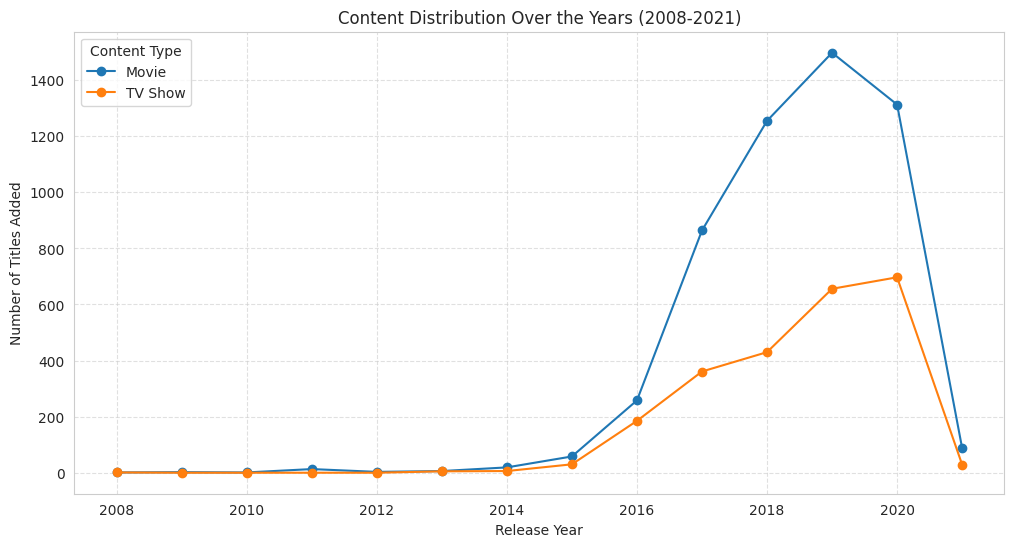


Content Distribution by Year:
type          Movie  TV Show
release_year                
2008              1        1
2009              2        0
2010              1        0
2011             13        0
2012              3        0
2013              6        5
2014             19        6
2015             58       30
2016            258      185
2017            864      361
2018           1255      430
2019           1498      656
2020           1313      697
2021             88       29


In [ ]:
# Objective 1: Movies vs. TV Shows Distribution over the years
content_over_time = df_filtered.groupby(['release_year', 'type']).size().unstack(fill_value=0)

# Plotting the trend
plt.figure(figsize=(12, 6))
content_over_time.plot(kind='line', marker='o', figsize=(12, 6))
plt.title('Content Distribution Over the Years (2008-2021)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Added')
plt.legend(title='Content Type')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(content_over_time.index[::2]) # Show every other year for cleaner look
plt.show()

print("\nContent Distribution by Year:")
print(content_over_time)


Top 10 Most Common Genres:
              Genre/Country  count
0      International Movies   2437
1                    Dramas   2108
2                  Comedies   1472
3    International TV Shows   1198
4             Documentaries    786
5        Action & Adventure    721
6                 TV Dramas    703
7        Independent Movies    675
8  Children & Family Movies    532
9           Romantic Movies    531


<Figure size 1500x700 with 0 Axes>

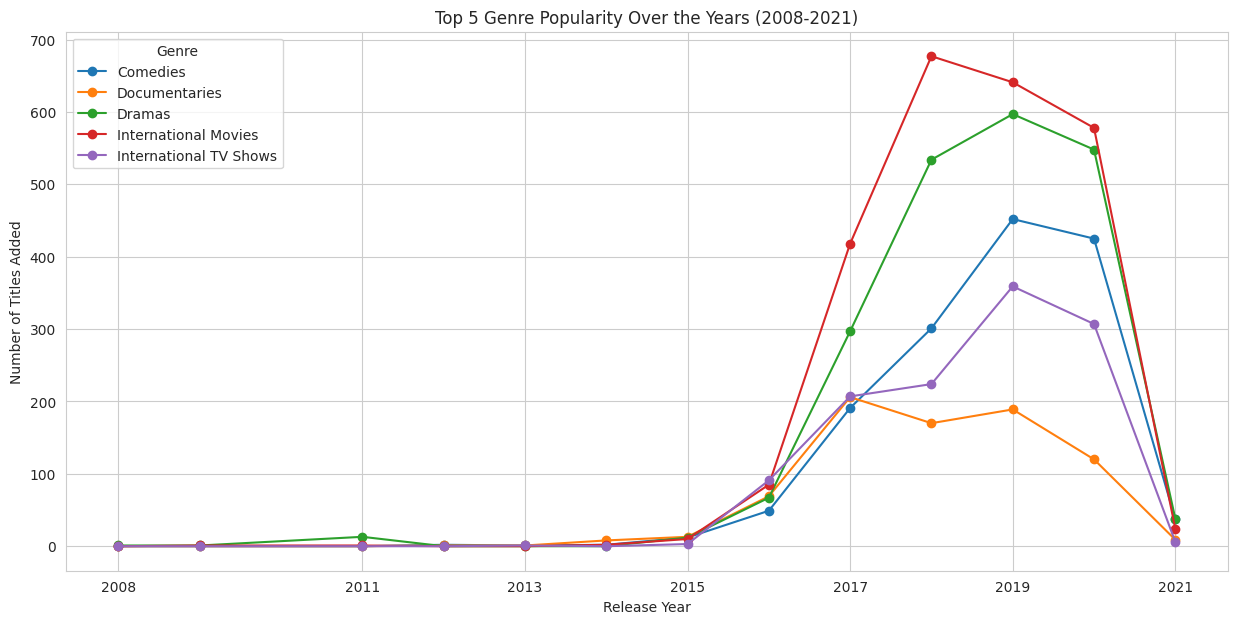

In [ ]:
# Objective 2: Most Common Genres and their change in popularity

# Function to split and count occurrences in a column
def count_occurrences(df, column):
    # Drop rows where the value is missing or 'Unspecified'
    df_clean = df.dropna(subset=[column]).copy()

    # Split the column and stack the values
    split_data = df_clean[column].str.split(', ', expand=True).stack()

    # Count the occurrences and return as a DataFrame
    return split_data.value_counts().reset_index().rename(columns={0: 'Count', 'index': 'Genre/Country'})

# Get the top 10 most common genres
genre_counts = count_occurrences(df_filtered, 'genre')
top_10_genres = genre_counts.head(10)

print("\nTop 10 Most Common Genres:")
print(top_10_genres)

# Further analysis: Genre popularity over time (for the top 5 genres)
top_5_names = top_10_genres['Genre/Country'].head(5).tolist()

# Prepare data for plotting genre trend over time
genre_trend = df_filtered.assign(genre=df_filtered['genre'].str.split(', ')).explode('genre')
genre_trend_filtered = genre_trend[genre_trend['genre'].isin(top_5_names)]

genre_over_time = genre_trend_filtered.groupby(['release_year', 'genre']).size().unstack(fill_value=0)

# Plotting genre popularity trends
plt.figure(figsize=(15, 7))
genre_over_time.plot(kind='line', marker='o', figsize=(15, 7))
plt.title('Top 5 Genre Popularity Over the Years (2008-2021)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Added')
plt.legend(title='Genre')
plt.xticks(genre_over_time.index[::2])
plt.show()

In [ ]:
# Objective 3: Compare country-wise contributions

# Count contributions per country (splitting multiple countries per title)
country_counts = count_occurrences(df_filtered, 'country')
top_10_countries = country_counts[country_counts['Genre/Country'] != 'Unspecified'].head(10)

print("\nTop 10 Countries by Content Contribution (excluding Unspecified):")
print(top_10_countries)

# Plotting the top 10 countries
plt.figure(figsize=(12, 6))
sns.barplot(x='Genre/Country', y='Count', data=top_10_countries, palette='viridis')
plt.title('Top 10 Content Contributing Countries on Netflix')
plt.xlabel('Country')
plt.ylabel('Number of Titles Added')
plt.xticks(rotation=45, ha='right') # Rotate country names for readability
plt.tight_layout()
plt.show()